In [1]:
import osmnx as ox
import geopandas as gpd

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

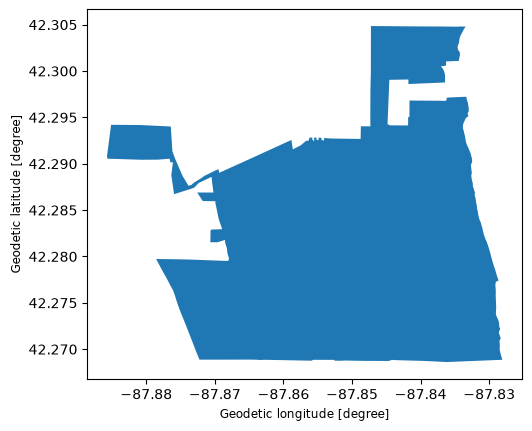

In [7]:
place = "Lake Bluff, Illinois, USA"
boundary = ox.geocode_to_gdf(place)
boundary.plot()

In [9]:
ox.settings.overpass_url = "https://overpass-api.de/api"
ox.settings.requests_timeout = 300

In [10]:
tags = {"leisure": "park"}
parks = ox.features_from_place(place, tags=tags)
parks.shape

(8, 6)

In [11]:
parks = parks[parks.geometry.type.isin(["Polygon", "MultiPolygon"])]
parks = parks.reset_index()
parks = parks[["name", "geometry"]]
parks.head()

,name,geometry
0,Blair Park,"POLYGON ((-87.8551 42.28034, -87.85523 42.2803..."
1,Birch Park,"POLYGON ((-87.88525 42.29286, -87.88543 42.291..."
2,Sanctuary Park,"POLYGON ((-87.88451 42.29075, -87.88397 42.291..."
3,Sunrise Park,"POLYGON ((-87.83034 42.27764, -87.8299 42.2776..."
4,Mawman Park,"POLYGON ((-87.84828 42.27704, -87.84756 42.276..."


In [12]:
parks.shape

(8, 2)

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

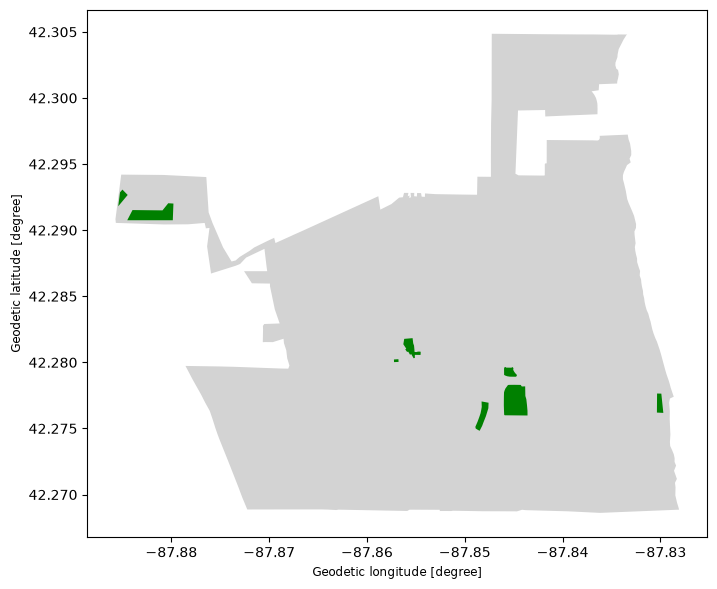

In [13]:
ax = boundary.plot(color="lightgrey", figsize=(8, 8))
parks.plot(ax=ax, color="green")

In [14]:
parks.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [18]:
parks.to_file("data/parks.gpkg")
boundary.to_file("data/boundary.gpkg")